In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
class Source:
    "Источник изотропного излучения фотонов"
    def __init__(self, Y: float = 10000):
        self.Y = Y

    def random_direction(self, E: float) ->np.ndarray:
        """Розыгрыш начального направления"""
        if E < 0:
            raise ValueError("Энергия может быть отрицательной")

        N = int(round(self.Y * E))

        phi = np.random.uniform(0, 2*np.pi, N)
        cosTheta = np.random.uniform(-1, 1, N)
        sinTheta = np.sqrt(1 - cosTheta**2)
        return np.array([sinTheta*np.cos(phi),
                         sinTheta*np.sin(phi),
                         cosTheta])

In [3]:
class Detector:
    "Сферический детектор "

    def __init__(self, R=2.0, N=40, r=0.1, a=0.5):
        self.R = R
        self.N = N
        self.r = r
        self.a = a

        self.p_positions = self.generate_positions()

    def generate_positions(self) -> np.ndarray:
        "Размещение ФЭУ"

        i = np.arange(self.N)
        z = self.R * (1 - 2 * (i + 0.5) / self.N)
        phi = i * np.pi * (3 - np.sqrt(5))
        rho = np.sqrt(self.R**2 - z**2)

        x = rho * np.cos(phi)
        y = rho * np.sin(phi)

        return np.column_stack((x, y, z))

    def is_on_pmt(self, point) -> bool:
        "Проверка принадлежности точки одному из ФЭУ "

        point = np.asarray(point)

        if not np.isclose(np.linalg.norm(point), self.R):
            return False

        distances = np.linalg.norm(
            self.p_positions - point, axis=1
        )

        return bool(np.any(distances <= self.r))

    def intersection(self, position, directions) -> np.ndarray:
        "Точки пересечения фотонов со сферой "
        position = np.asarray(position, dtype= float)

        if np.linalg.norm(position) >= self.R:
            return None

        b = position @ directions

        # Расстояния до поверхности детектора
        t = -b + np.sqrt(b**2 + self.R**2 - np.dot(position, position))

        # Все точки пересечения
        return position[:, None] + directions * t[None, :]

    def photon_hits(self, points) -> np.ndarray:
        "Определяет, в какой фотоумножитель попадёт фотон "
        distances2 = np.sum(
            (points.T[:, None, :] -
             self.p_positions[None, :, :])**2,
            axis=2
        )

        # Ближайший фотоумножитель к каждому фотону
        nearest = np.argmin(distances2, axis=1)

        hits = distances2[
            np.arange(points.shape[1]), nearest
        ] <= self.r**2

        return np.bincount(
            nearest[hits], minlength=self.N
        )

    def photoelectrons(self, n_photons=1):
        "Возвращает случайное число фотоэлектронов по распределению Пуассона со средним a "

        return np.random.poisson(self.a * n_photons)


In [4]:
np.random.seed(42)
source = Source(Y=10000)
detector = Detector(R=2.0, N=40, r=0.1, a=0.5)
E = 1.0
L_att = 8.0
positions_z = np.array([-1.5, -1.0, 0.0, 1.0, 1.5])  # внутри сферы R=2 м
n_events = 300

In [5]:
def simulate_pair(E, position, L_att=8.0):
    """Возвращает (Q_без_затухания, Q_с_затуханием) при общих направлениях """
    directions = source.random_direction(E)
    points = detector.intersection(position, directions)

    # Длина пути от источника до точки пересечения со сферой
    lengths = np.linalg.norm(points - position[:, None], axis=0)

    # все фотоны достигают стенки детектора
    n_hits_no = detector.photon_hits(points)

    # затухание
    p_survival = np.exp(-lengths / L_att)
    survived = np.random.random(size=lengths.size) < p_survival
    n_hits_att = detector.photon_hits(points[:, survived])

    q_no = int(np.sum(detector.photoelectrons(n_hits_no)))
    q_att = int(np.sum(detector.photoelectrons(n_hits_att)))
    return q_no, q_att

In [7]:
position = np.array([0.0, 0.0, 0.0])
q_no, q_att = simulate_pair(E, position, L_att)
print(f"Центр, E={E} МэВ: без затухания Q={q_no}, с затуханием Q={q_att}")
print(f"Теоретическая выживаемость в центре: {np.exp(-detector.R/L_att):.3f}")

Центр, E=1.0 МэВ: без затухания Q=125, с затуханием Q=90
Теоретическая выживаемость в центре: 0.779


In [8]:
responses_no = {}
responses_att = {}

for z in positions_z:
    position = np.array([0.0, 0.0, float(z)])
    pairs = np.array([simulate_pair(E, position, L_att) for _ in range(n_events)])
    responses_no[z] = pairs[:, 0]
    responses_att[z] = pairs[:, 1]
    print(f"z={z:+.1f} м: "
          f"<Q> без = {responses_no[z].mean():.2f}, "
          f"<Q> с = {responses_att[z].mean():.2f}")

z=-1.5 м: <Q> без = 122.69, <Q> с = 100.59
z=-1.0 м: <Q> без = 125.91, <Q> с = 100.10
z=+0.0 м: <Q> без = 125.80, <Q> с = 97.62
z=+1.0 м: <Q> без = 124.71, <Q> с = 99.65
z=+1.5 м: <Q> без = 122.02, <Q> с = 100.10


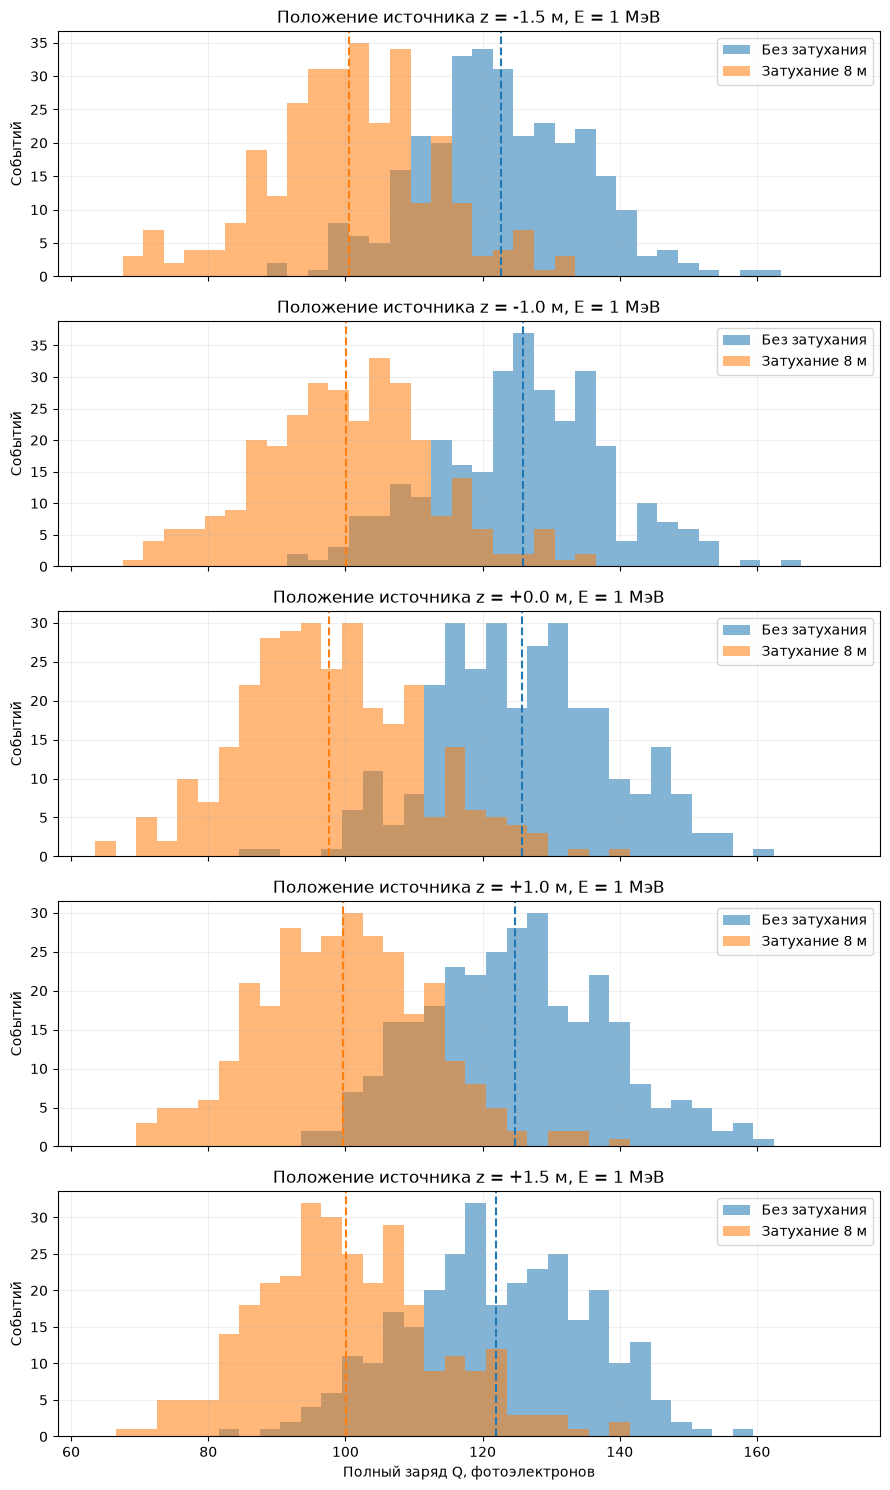

In [9]:
fig, axes = plt.subplots(len(positions_z), 1, figsize=(9, 3*len(positions_z)), sharex=True)
for ax, z in zip(axes, positions_z):
    a = responses_no[z]
    b = responses_att[z]
    bins = np.arange(min(a.min(), b.min()) - 0.5, max(a.max(), b.max()) + 1.5, 3)
    ax.hist(a, bins=bins, alpha=0.55, label='Без затухания')
    ax.hist(b, bins=bins, alpha=0.55, label='Затухание 8 м')
    ax.axvline(a.mean(), ls='--', color='C0')
    ax.axvline(b.mean(), ls='--', color='C1')
    ax.set_title(f'Положение источника z = {z:+.1f} м, E = 1 МэВ')
    ax.set_ylabel('Событий')
    ax.legend()
    ax.grid(alpha=0.2)
axes[-1].set_xlabel('Полный заряд Q, фотоэлектронов')
plt.tight_layout()
plt.show()

z, м | <Q> без | <Q> с | отношение | снижение, %
-1.5  |  122.69 | 100.59 |    0.820 |      18.0
-1.0  |  125.91 | 100.10 |    0.795 |      20.5
+0.0  |  125.80 |  97.62 |    0.776 |      22.4
+1.0  |  124.71 |  99.65 |    0.799 |      20.1
+1.5  |  122.02 | 100.10 |    0.820 |      18.0


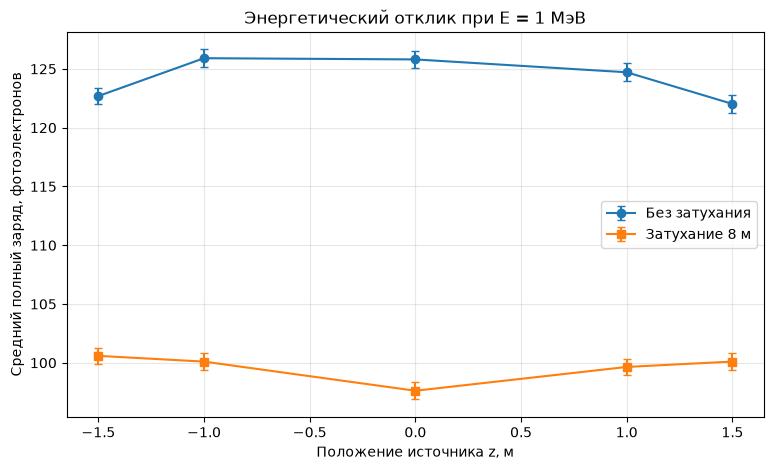

In [10]:
mean_no = np.array([responses_no[z].mean() for z in positions_z])
mean_att = np.array([responses_att[z].mean() for z in positions_z])
std_no = np.array([responses_no[z].std(ddof=1) for z in positions_z])
std_att = np.array([responses_att[z].std(ddof=1) for z in positions_z])

print('z, м | <Q> без | <Q> с | отношение | снижение, %')
for z, q0, q1 in zip(positions_z, mean_no, mean_att):
    print(f'{z:+4.1f}  | {q0:7.2f} | {q1:6.2f} | {q1/q0:8.3f} | {100*(1-q1/q0):9.1f}')

plt.figure(figsize=(9, 5))
plt.errorbar(positions_z, mean_no, yerr=std_no/np.sqrt(n_events), fmt='o-', capsize=3, label='Без затухания')
plt.errorbar(positions_z, mean_att, yerr=std_att/np.sqrt(n_events), fmt='s-', capsize=3, label='Затухание 8 м')
plt.xlabel('Положение источника z, м')
plt.ylabel('Средний полный заряд, фотоэлектронов')
plt.title('Энергетический отклик при E = 1 МэВ')
plt.grid(alpha=0.3)
plt.legend()
plt.show()

In [12]:
assert np.all(mean_att < mean_no)

# Для центрального источника
idx0 = np.where(positions_z == 0.0)[0][0]
ratio_center = mean_att[idx0] / mean_no[idx0]
expected_center = np.exp(-detector.R / L_att)
print(f'В центре: отношение средних = {ratio_center:.3f}, теория = {expected_center:.3f}')

В центре: отношение средних = 0.776, теория = 0.779
